In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import os

print("Tudo importado!")

Tudo importado!


In [2]:
caminho_base = "."

sets = {
    "Z": {"nome": "Set A - Saudável (olhos abertos)", "rotulo": 0},
    "O": {"nome": "Set B - Saudável (olhos fechados)", "rotulo": 0},
    "N": {"nome": "Set C - Interictal (fora da zona)", "rotulo": 1},
    "F": {"nome": "Set D - Interictal (zona epileptogênica)", "rotulo": 1},
    "S": {"nome": "Set E - Crise epiléptica (ictal)", "rotulo": 2},
}

sinais = []
rotulos = []
origens = []

for pasta, info in sets.items():
    caminho_pasta = os.path.join(caminho_base, pasta)
    arquivos = sorted([f for f in os.listdir(caminho_pasta) if f.lower().endswith('.txt')])
    
    for arquivo in arquivos:
        caminho_arquivo = os.path.join(caminho_pasta, arquivo)
        sinal = np.loadtxt(caminho_arquivo)
        sinais.append(sinal)
        rotulos.append(info["rotulo"])
        origens.append(info["nome"])

sinais = np.array(sinais, dtype=np.float32)
rotulos = np.array(rotulos, dtype=np.int64)

print(f"Total de sinais carregados: {len(sinais)}")
print(f"\nDistribuição das classes:")
print(f"  Classe 0 (saudável):   {(rotulos == 0).sum()} sinais")
print(f"  Classe 1 (interictal): {(rotulos == 1).sum()} sinais")
print(f"  Classe 2 (crise):      {(rotulos == 2).sum()} sinais")

Total de sinais carregados: 500

Distribuição das classes:
  Classe 0 (saudável):   200 sinais
  Classe 1 (interictal): 200 sinais
  Classe 2 (crise):      100 sinais


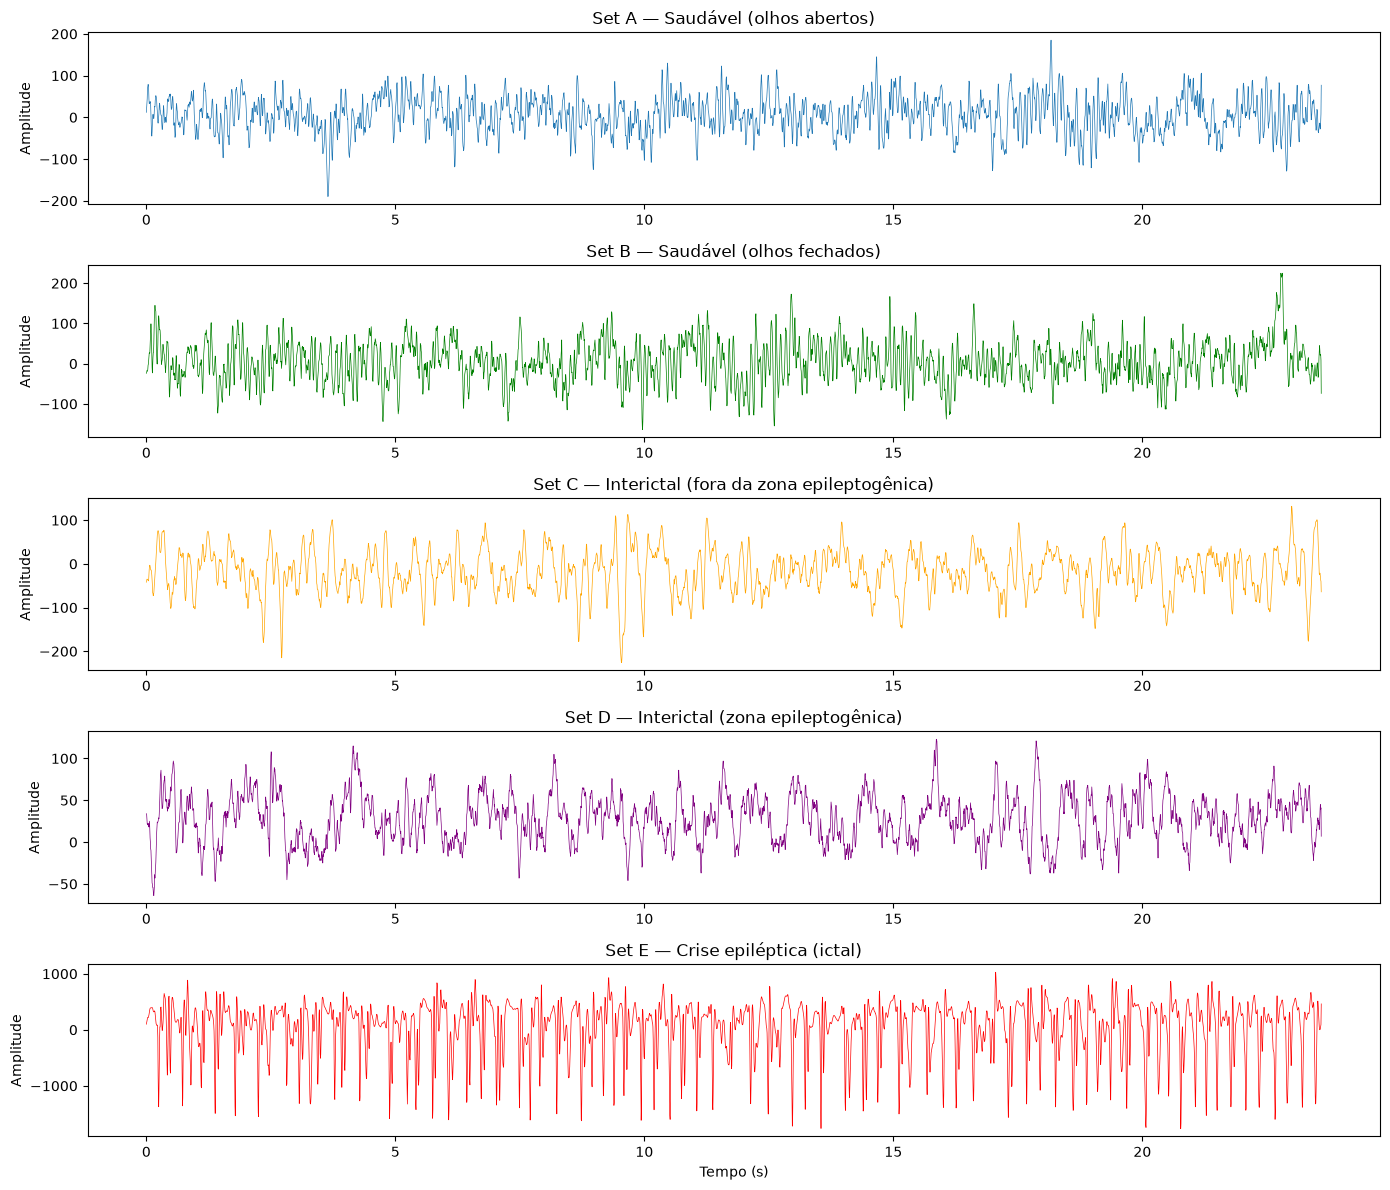

In [3]:
t_eeg = np.arange(4097) / 173.61

fig, eixos = plt.subplots(5, 1, figsize=(14, 12))

# Set A — Saudável (olhos abertos) — primeiros 100 sinais
eixos[0].plot(t_eeg, sinais[0], linewidth=0.5)
eixos[0].set_title("Set A — Saudável (olhos abertos)")
eixos[0].set_ylabel("Amplitude")

# Set B — Saudável (olhos fechados) — sinais 100 a 199
eixos[1].plot(t_eeg, sinais[100], linewidth=0.5, color='green')
eixos[1].set_title("Set B — Saudável (olhos fechados)")
eixos[1].set_ylabel("Amplitude")

# Set C — Interictal fora da zona — sinais 200 a 299
eixos[2].plot(t_eeg, sinais[200], linewidth=0.5, color='orange')
eixos[2].set_title("Set C — Interictal (fora da zona epileptogênica)")
eixos[2].set_ylabel("Amplitude")

# Set D — Interictal zona epileptogênica — sinais 300 a 399
eixos[3].plot(t_eeg, sinais[300], linewidth=0.5, color='purple')
eixos[3].set_title("Set D — Interictal (zona epileptogênica)")
eixos[3].set_ylabel("Amplitude")

# Set E — Crise — sinais 400 a 499
eixos[4].plot(t_eeg, sinais[400], linewidth=0.5, color='red')
eixos[4].set_title("Set E — Crise epiléptica (ictal)")
eixos[4].set_ylabel("Amplitude")
eixos[4].set_xlabel("Tempo (s)")

plt.tight_layout()
plt.show()

In [4]:
duracao_janela = 2.0
taxa = 173.61
pontos_por_janela = int(duracao_janela * taxa)

print(f"Duração da janela: {duracao_janela} s")
print(f"Pontos por janela: {pontos_por_janela}")

janelas = []
rotulos_janelas = []

for i in range(len(sinais)):
    sinal = sinais[i]
    rotulo = rotulos[i]
    num_janelas = len(sinal) // pontos_por_janela
    
    for j in range(num_janelas):
        inicio = j * pontos_por_janela
        fim = inicio + pontos_por_janela
        janela = sinal[inicio:fim]
        janelas.append(janela)
        rotulos_janelas.append(rotulo)

janelas = np.array(janelas, dtype=np.float32)
rotulos_janelas = np.array(rotulos_janelas, dtype=np.int64)

print(f"\nTotal de janelas: {len(janelas)}")
print(f"Formato de cada janela: {janelas[0].shape}")
print(f"Classe 0 (saudável):   {(rotulos_janelas == 0).sum()} janelas")
print(f"Classe 1 (interictal): {(rotulos_janelas == 1).sum()} janelas")
print(f"Classe 2 (crise):      {(rotulos_janelas == 2).sum()} janelas")

Duração da janela: 2.0 s
Pontos por janela: 347

Total de janelas: 5500
Formato de cada janela: (347,)
Classe 0 (saudável):   2200 janelas
Classe 1 (interictal): 2200 janelas
Classe 2 (crise):      1100 janelas


In [5]:
janelas_treino, janelas_teste, rot_treino, rot_teste = train_test_split(
    janelas, rotulos_janelas, test_size=0.2, random_state=42, stratify=rotulos_janelas
)

print(f"Treino: {len(janelas_treino)} janelas")
print(f"Teste:  {len(janelas_teste)} janelas")
print(f"\nTreino — Classe 0: {(rot_treino == 0).sum()}, Classe 1: {(rot_treino == 1).sum()}, Classe 2: {(rot_treino == 2).sum()}")
print(f"Teste  — Classe 0: {(rot_teste == 0).sum()}, Classe 1: {(rot_teste == 1).sum()}, Classe 2: {(rot_teste == 2).sum()}")

Treino: 4400 janelas
Teste:  1100 janelas

Treino — Classe 0: 1760, Classe 1: 1760, Classe 2: 880
Teste  — Classe 0: 440, Classe 1: 440, Classe 2: 220


In [6]:
media_treino = janelas_treino.mean()
desvio_treino = janelas_treino.std()

janelas_treino_norm = (janelas_treino - media_treino) / desvio_treino
janelas_teste_norm = (janelas_teste - media_treino) / desvio_treino

print(f"Média do treino: {media_treino:.4f}")
print(f"Desvio padrão: {desvio_treino:.4f}")
print(f"\nApós normalização:")
print(f"  Treino — média: {janelas_treino_norm.mean():.4f}, desvio: {janelas_treino_norm.std():.4f}")
print(f"  Teste  — média: {janelas_teste_norm.mean():.4f}, desvio: {janelas_teste_norm.std():.4f}")

Média do treino: -7.5759
Desvio padrão: 163.9566

Após normalização:
  Treino — média: 0.0000, desvio: 1.0000
  Teste  — média: -0.0015, desvio: 1.0354


In [7]:
# Converter para tensores
X_treino = torch.FloatTensor(janelas_treino_norm).unsqueeze(1)  # adiciona canal
y_treino = torch.LongTensor(rot_treino)
X_teste = torch.FloatTensor(janelas_teste_norm).unsqueeze(1)
y_teste = torch.LongTensor(rot_teste)

print(f"X_treino: {X_treino.shape}  (batch, canal, pontos)")
print(f"X_teste:  {X_teste.shape}")

# DataLoaders
dataset_treino = TensorDataset(X_treino, y_treino)
dataset_teste = TensorDataset(X_teste, y_teste)

loader_treino = DataLoader(dataset_treino, batch_size=64, shuffle=True)
loader_teste = DataLoader(dataset_teste, batch_size=64, shuffle=False)

print(f"\nBatches de treino: {len(loader_treino)}")
print(f"Batches de teste: {len(loader_teste)}")

X_treino: torch.Size([4400, 1, 347])  (batch, canal, pontos)
X_teste:  torch.Size([1100, 1, 347])

Batches de treino: 69
Batches de teste: 18


In [8]:
class DatasetAugmentado(torch.utils.data.Dataset):
    """
    Dataset que aplica augmentation aleatório a cada leitura.
    Só para treino — teste continua sem augmentation.
    """
    def __init__(self, sinais, rotulos, augmentar=True):
        self.sinais = sinais      # tensores já normalizados
        self.rotulos = rotulos
        self.augmentar = augmentar
    
    def __len__(self):
        return len(self.sinais)
    
    def __getitem__(self, idx):
        sinal = self.sinais[idx].clone()  # clone para não alterar o original
        rotulo = self.rotulos[idx]
        
        if self.augmentar:
            # Transformação 1: adicionar ruído gaussiano leve
            # Desvio de 0.05 significa ruído com 5% da amplitude normalizada
            ruido = torch.randn_like(sinal) * 0.05
            sinal = sinal + ruido
            
            # Transformação 2: escalar amplitude aleatoriamente entre 0.8x e 1.2x
            escala = 0.8 + torch.rand(1).item() * 0.4  # valor entre 0.8 e 1.2
            sinal = sinal * escala
        
        return sinal, rotulo

# Cria dataset augmentado para treino (com augmentation)
dataset_treino_aug = DatasetAugmentado(X_treino, y_treino, augmentar=True)

# Teste continua sem augmentation (usando o TensorDataset normal que já existe)
# dataset_teste já foi criado na célula 7

# Recria o DataLoader de treino usando o dataset augmentado
loader_treino = DataLoader(dataset_treino_aug, batch_size=64, shuffle=True)

# Verifica: lê a mesma amostra duas vezes
amostra1, _ = dataset_treino_aug[0]
amostra2, _ = dataset_treino_aug[0]
iguais = torch.equal(amostra1, amostra2)
print(f"Duas leituras da mesma amostra são iguais? {iguais}")
print("(Se False, o augmentation está funcionando)")
print(f"\nBatches de treino: {len(loader_treino)}")

Duas leituras da mesma amostra são iguais? False
(Se False, o augmentation está funcionando)

Batches de treino: 69


In [9]:
class CNN1D_EEG(nn.Module):
    def __init__(self):
        super().__init__()
        
        # Parte convolucional
        self.conv1 = nn.Conv1d(in_channels=1, out_channels=16, kernel_size=7, padding=3)
        self.pool = nn.MaxPool1d(kernel_size=2)
        self.conv2 = nn.Conv1d(in_channels=16, out_channels=32, kernel_size=5, padding=2)
        
        # Truque: descobre o tamanho depois do achatamento automaticamente
        # Passa um tensor fictício pelas convoluções para ver o tamanho que sai
        with torch.no_grad():
            ficticio = torch.zeros(1, 1, pontos_por_janela)  # 1 amostra, 1 canal, pontos_por_janela = int(duracao_janela * taxa)
            ficticio = self.pool(self.conv1(ficticio))
            ficticio = self.pool(self.conv2(ficticio))
            tamanho_achatado = ficticio.view(1, -1).shape[1]
        
        print(f"Tamanho após achatamento: {tamanho_achatado}")
        
        # Parte densa
        self.fc1 = nn.Linear(tamanho_achatado, 64)
        self.fc2 = nn.Linear(64, 3)  # 3 classes: saudável vs interictal vs crise
        
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(p=0.2)
    
    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = x.view(x.size(0), -1)
        x = self.dropout(self.relu(self.fc1(x)))
        x = self.fc2(x)
        return x

modelo = CNN1D_EEG()
print(modelo)
total_params = sum(p.numel() for p in modelo.parameters())
print(f"\nTotal de parâmetros: {total_params:,}")

Tamanho após achatamento: 2752
CNN1D_EEG(
  (conv1): Conv1d(1, 16, kernel_size=(7,), stride=(1,), padding=(3,))
  (pool): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv1d(16, 32, kernel_size=(5,), stride=(1,), padding=(2,))
  (fc1): Linear(in_features=2752, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=3, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.2, inplace=False)
)

Total de parâmetros: 179,107


In [10]:
criterio = nn.CrossEntropyLoss()
otimizador = optim.Adam(modelo.parameters(), lr=0.001)
scheduler = optim.lr_scheduler.StepLR(otimizador, step_size=6, gamma=0.5)

num_epocas = 40
for epoca in range(num_epocas):
    modelo.train()
    perda_acumulada = 0.0
    acertos = 0
    total = 0
    
    for entradas, rotulos_batch in loader_treino:
        otimizador.zero_grad()
        saidas = modelo(entradas)
        perda = criterio(saidas, rotulos_batch)
        perda.backward()
        otimizador.step()
        
        perda_acumulada += perda.item()
        _, previstos = saidas.max(1)
        acertos += (previstos == rotulos_batch).sum().item()
        total += rotulos_batch.size(0)
    
    scheduler.step()
    lr_atual = otimizador.param_groups[0]['lr']
    perda_media = perda_acumulada / len(loader_treino)
    acuracia = 100 * acertos / total
    print(f"Época {epoca+1}/{num_epocas} — Perda: {perda_media:.4f} — Acurácia: {acuracia:.2f}% — LR: {lr_atual:.6f}")

print("\nTreinamento concluído!")

Época 1/40 — Perda: 0.6541 — Acurácia: 67.25% — LR: 0.001000
Época 2/40 — Perda: 0.4014 — Acurácia: 83.91% — LR: 0.001000
Época 3/40 — Perda: 0.3294 — Acurácia: 87.00% — LR: 0.001000
Época 4/40 — Perda: 0.3031 — Acurácia: 87.77% — LR: 0.001000
Época 5/40 — Perda: 0.2691 — Acurácia: 89.73% — LR: 0.001000
Época 6/40 — Perda: 0.2383 — Acurácia: 90.73% — LR: 0.000500
Época 7/40 — Perda: 0.2039 — Acurácia: 92.59% — LR: 0.000500
Época 8/40 — Perda: 0.1859 — Acurácia: 92.98% — LR: 0.000500
Época 9/40 — Perda: 0.1853 — Acurácia: 93.30% — LR: 0.000500
Época 10/40 — Perda: 0.1695 — Acurácia: 93.66% — LR: 0.000500
Época 11/40 — Perda: 0.1662 — Acurácia: 93.75% — LR: 0.000500
Época 12/40 — Perda: 0.1521 — Acurácia: 94.61% — LR: 0.000250
Época 13/40 — Perda: 0.1394 — Acurácia: 95.16% — LR: 0.000250
Época 14/40 — Perda: 0.1415 — Acurácia: 94.66% — LR: 0.000250
Época 15/40 — Perda: 0.1285 — Acurácia: 95.48% — LR: 0.000250
Época 16/40 — Perda: 0.1291 — Acurácia: 95.39% — LR: 0.000250
Época 17/40 — Per

In [11]:
modelo.eval()
acertos = 0
total = 0

with torch.no_grad():
    for entradas, rotulos_batch in loader_teste:
        saidas = modelo(entradas)
        _, previstos = saidas.max(1)
        acertos += (previstos == rotulos_batch).sum().item()
        total += rotulos_batch.size(0)

acuracia_teste = 100 * acertos / total
print(f"Acurácia no teste: {acuracia_teste:.2f}%")
print(f"Acertos: {acertos}/{total}")

Acurácia no teste: 95.36%
Acertos: 1049/1100


In [12]:
from sklearn.metrics import confusion_matrix, classification_report

modelo.eval()

todas_previsoes = []
todos_rotulos = []

with torch.no_grad():
    for entradas, rotulos_batch in loader_teste:
        saidas = modelo(entradas)
        _, previstos = saidas.max(1)
        todas_previsoes.extend(previstos.numpy())
        todos_rotulos.extend(rotulos_batch.numpy())

# Matriz de confusão
nomes_classes = ["Saudável", "Interictal", "Crise"]
cm = confusion_matrix(todos_rotulos, todas_previsoes)

print("=== MATRIZ DE CONFUSÃO ===\n")
print(f"{'':>12} {'Prev Saud':>12} {'Prev Inter':>12} {'Prev Crise':>12}")
for i, nome in enumerate(nomes_classes):
    print(f"{nome:>12} {cm[i][0]:>12} {cm[i][1]:>12} {cm[i][2]:>12}")

print(f"\n=== RELATÓRIO DE CLASSIFICAÇÃO ===\n")
print(classification_report(todos_rotulos, todas_previsoes, target_names=nomes_classes))

=== MATRIZ DE CONFUSÃO ===

                Prev Saud   Prev Inter   Prev Crise
    Saudável          416           24            0
  Interictal           18          420            2
       Crise            3            4          213

=== RELATÓRIO DE CLASSIFICAÇÃO ===

              precision    recall  f1-score   support

    Saudável       0.95      0.95      0.95       440
  Interictal       0.94      0.95      0.95       440
       Crise       0.99      0.97      0.98       220

    accuracy                           0.95      1100
   macro avg       0.96      0.96      0.96      1100
weighted avg       0.95      0.95      0.95      1100

